# Figure 3 — Early dynamics in the four MF lines (1, 3, 5, 7 hpf)

**Run order:** fig2 → **fig3** → fig5 → fig6. Fig 6E reads the cluster assignments written here.

| Output | What | File (in `outputs/`) |
|---|---|---|
| **Fig 3A** (right) | Ind / Byn / Peb profiles, one panel per line | `fig3/fig3A_gene_profiles` |
| **Fig 3B** | Shared K-means clusters (K = 12), median profile per line; fate clusters boxed | `fig3/fig3B_cluster_heatmap` |
| **Fig 3C** | GO enrichment of clusters 3, 6, 8, 9 | `fig3/fig3C_go_enrichment` |
| **Fig 3D** | 7 hpf abundance of cluster 9, per line | `fig3/fig3D_violin_7hpf_cluster9` |
| **Fig 3E** | % of proteome differentially abundant between lines, 7 hpf | `fig3/fig3E_pct_matrix_7hpf` |
| **Supplementary Table S2** | Time course, all proteins, with cluster | `supplementary_tables/Table_S2_MF_timecourse_clusters.csv` |
| **Supplementary Table S3** | Proteins in fate-specific clusters 6, 8, 9 | `supplementary_tables/Table_S3_MF_fate_cluster_proteins.csv` |
| **Supplementary Table S4** | All proteins at 7 hpf + log2FC / q / sig for the 6 comparisons | `supplementary_tables/Table_S4_MF_lines_7hpf.csv` |
| *for Fig 6E* | Cluster assignment of every protein | `intermediate/mf_timecourse_clusters.csv` |

Fig 3A (left) is a schematic. Fig S2B (7 hpf replicate concordance) is made in the fig2 notebook.

**Inputs:** `raw data/protein_quant_2245_cns19b.tsv` (time course), `helper files/figure3_go_reference.csv` (optional, offline Fig 3C),
`raw data/protein_quant_2229_cns16_b4.tsv` (Fig 3E, Table S4), `helper files/genetable.xlsx`.

**Cluster numbering.** Raw K-means labels are renumbered 1–12 by size (largest first); all panels use these numbers.
Fig 3C queries the g:Profiler web service (needs internet unless `GO_MODE = 'reference'`).

In [1]:
import re
import textwrap
import warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from sklearn.cluster import KMeans

import common as cm

OUT = cm.fig_dir('fig3')
QUANT_FILE   = cm.DATA_DIR / 'protein_quant_2245_cns19b.tsv'
GO_REFERENCE = cm.HELPER_DIR / 'figure3_go_reference.csv'
cm.require(QUANT_FILE, cm.GENETABLE)

# ── Analysis parameters ──
MIN_SUM_SN  = 360      # summed S/N over the 16 channels
K           = 12
KMEANS_SEED = 42

# ── Panel choices (display cluster numbers, 1 = largest) ──
PANEL_A_GENES  = ['ind', 'byn', 'peb']
FATE_CLUSTERS  = [6, 8, 9]       # boxed in 3B; Table S3
GO_CLUSTERS    = [9, 6, 3, 8]    # 3C, top -> bottom
VIOLIN_CLUSTER = 9               # 3D
GO_MODE        = 'auto'          # 'auto': g:Profiler, fall back to GO_REFERENCE if offline
                                 # 'live': g:Profiler only;  'reference': redraw the published panel

# Cluster sizes of the published run; a warning is raised if the clustering changes
EXPECTED_SIZES = {1: 2108, 2: 2081, 3: 1005, 4: 404, 5: 304, 6: 91,
                  7: 82, 8: 35, 9: 33, 10: 25, 11: 15, 12: 12}

mpl.rcParams.update({
    'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
    'xtick.labelsize': 13, 'ytick.labelsize': 13, 'axes.linewidth': 2.0,
})

## Load and normalise the time course
`r6matt` = lateral proctodeum, `r67` = neuroectoderm, `2cr6` = dorsal proctodeum, `ea21` = dorsal ectoderm;
`0to1` = 1 hpf, `B0` = 3 hpf, `B2` = 5 hpf, `B4` = 7 hpf.

In [2]:
all_channels = ['126_sn', '127n_sn', '127c_sn', '128n_sn', '128c_sn', '129n_sn', '129c_sn', '130n_sn',
                '130c_sn', '131n_sn', '131c_sn', '132n_sn', '132c_sn', '133n_sn', '133c_sn', '134n_sn']
experiment_channels = ['r6matt_0to1', '2cr6_0to1', 'ea21bot_0to1', 'r67_0to1',
                       'r67_B0', 'r6matt_B0', '2cr6_B0', 'ea21botspz_B0',
                       'r67_B2', 'r6matt_B2', '2cr6_B2', 'ea21botspz_B2',
                       'r67_B4', 'r6matt_B4', '2cr6_B4', 'ea21botspz_B4']
result = cm.normalize_tmt(QUANT_FILE, all_channels, experiment_channels, MIN_SUM_SN)

prefix_to_condition = {'r6matt': 'lateral proctodeum', 'r67': 'neuroectoderm',
                       '2cr6': 'dorsal proctodeum', 'ea21': 'dorsal ectoderm'}
condition_order   = ['lateral proctodeum', 'neuroectoderm', 'dorsal proctodeum', 'dorsal ectoderm']
timepoint_order   = ['0to1', 'B0', 'B2', 'B4']
timepoint_display = ['1 hpf', '3 hpf', '5 hpf', '7 hpf']

# condition -> its 4 columns in time order
condition_columns = {c: [None] * len(timepoint_order) for c in condition_order}
for ch in experiment_channels:
    cond = next(c for pre, c in prefix_to_condition.items() if ch.startswith(pre))
    tp   = next(t for t in timepoint_order if ch.endswith('_' + t))
    condition_columns[cond][timepoint_order.index(tp)] = f'{ch}_norm'

channel_columns = [f'{ch}_norm' for ch in experiment_channels]
result[channel_columns] = result[channel_columns].apply(pd.to_numeric, errors='coerce')

protein_quant_2245_cns19b.tsv: 6475 rows -> 6213 pass S/N + decoy filter -> 6195 with gene annotation


## Shared K-means clustering (K = 12)
One fit on all proteins with complete 16-channel profiles (no scaling). Clusters renumbered 1…K by size.

In [3]:
X = result[channel_columns].dropna()
km = KMeans(n_clusters=K, random_state=KMEANS_SEED, n_init=10)
raw_labels = km.fit_predict(X)

sizes = pd.Series(raw_labels).value_counts()
rank  = sorted(sizes.index, key=lambda c: (-sizes[c], -km.cluster_centers_[c].mean()))
raw_to_display = {int(r): i + 1 for i, r in enumerate(rank)}

result['cluster'] = pd.Series(pd.NA, index=result.index, dtype='Int64')
result.loc[X.index, 'cluster'] = [raw_to_display[int(r)] for r in raw_labels]

cluster_sizes = result['cluster'].value_counts().sort_index()
print(f'K-means (K={K}) on {len(X)} proteins; sizes: {cluster_sizes.to_dict()}')
if cluster_sizes.to_dict() != EXPECTED_SIZES:
    warnings.warn('Cluster sizes differ from the published run - check FATE_CLUSTERS / GO_CLUSTERS / '
                  'VIOLIN_CLUSTER before using the panels.')

# For Fig 6E
result[['ProteinId', 'gene_symbol', 'cluster']].to_csv(cm.INTERMEDIATE_DIR / 'mf_timecourse_clusters.csv', index=False)

K-means (K=12) on 6195 proteins; sizes: {np.int64(1): 2108, np.int64(2): 2081, np.int64(3): 1005, np.int64(4): 404, np.int64(5): 304, np.int64(6): 91, np.int64(7): 82, np.int64(8): 35, np.int64(9): 33, np.int64(10): 25, np.int64(11): 15, np.int64(12): 12}


## Fig 3A — gene profiles across time, one panel per line

Saved fig3/fig3A_gene_profiles.pdf / .png


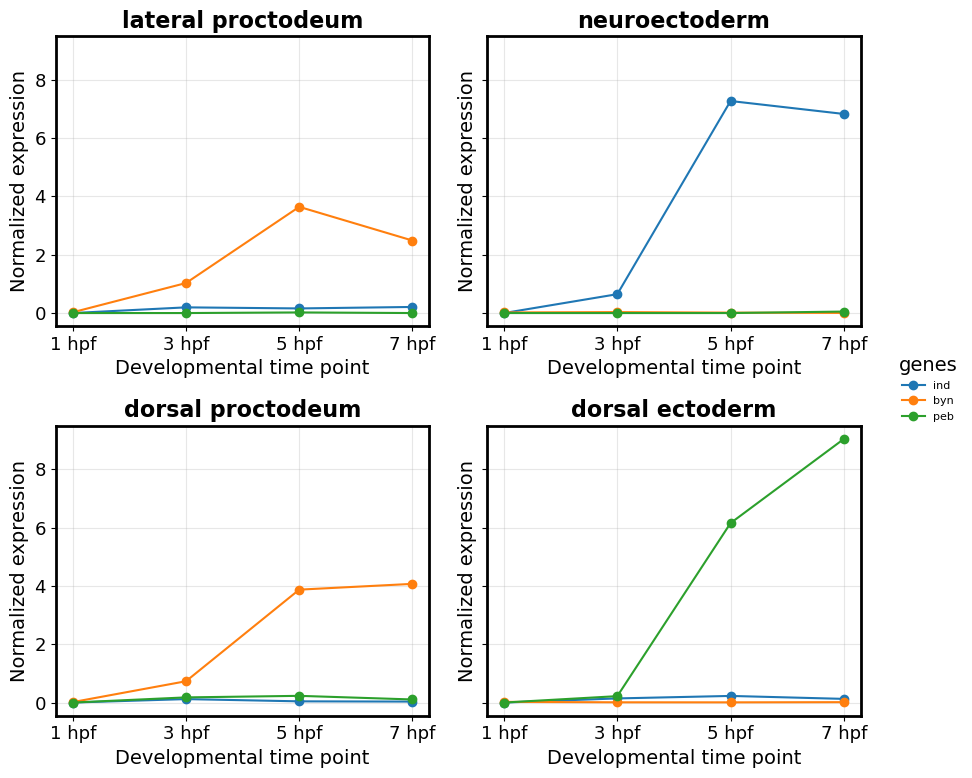

In [4]:
series = []
for g in PANEL_A_GENES:
    rows = result[result['gene_symbol'] == g]
    for _, row in rows.iterrows():
        label = f"{g} ({row['Reference']})" if len(rows) > 1 and 'Reference' in row else g
        series.append((label, {c: row[condition_columns[c]].to_numpy(float) for c in condition_order}))
colors = [plt.get_cmap('tab10')(i) for i in range(len(series))]

fig, axes = plt.subplots(2, 2, figsize=(10, 8), squeeze=False, sharey=True)
x = range(len(timepoint_display))
for ax, cond in zip(axes.ravel(), condition_order):
    for (label, vals), color in zip(series, colors):
        ax.plot(x, vals[cond], marker='o', color=color, label=label)
    ax.set_title(cond, fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels(timepoint_display)
    ax.set_xlabel('Developmental time point'); ax.set_ylabel('Normalized expression')
    ax.grid(True, alpha=0.3)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.9, 0.5), fontsize=8, frameon=False, title='genes')
fig.tight_layout(rect=[0, 0, 0.9, 1])
cm.save_fig(fig, OUT, 'fig3A_gene_profiles')
plt.show()

## Fig 3B — median temporal profile per cluster and line
Colour range shared across the four panels (2nd–98th percentile of the cluster medians).

Saved fig3/fig3B_cluster_heatmap.pdf / .png


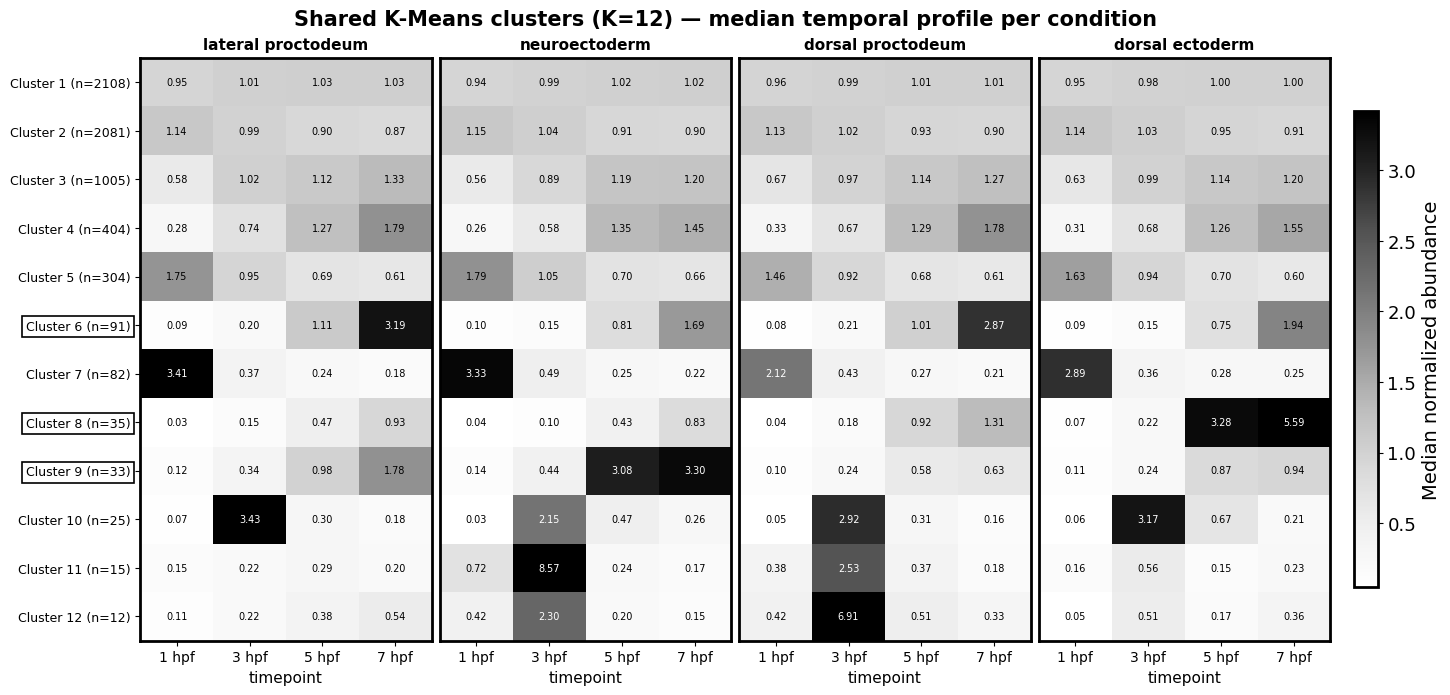

In [5]:
clusters   = sorted(int(c) for c in result['cluster'].dropna().unique())
row_labels = [f'Cluster {c} (n={cluster_sizes[c]})' for c in clusters]
mats = {cond: result.groupby('cluster')[condition_columns[cond]].median().reindex(clusters).to_numpy()
        for cond in condition_order}
vmin, vmax = np.nanpercentile(np.concatenate([m.ravel() for m in mats.values()]), [2, 98])
norm, cmap = Normalize(vmin, vmax), plt.get_cmap('Greys')

fig, axes = plt.subplots(1, 4, figsize=(3.6 * 4, 0.42 * len(clusters) + 1.8),
                         squeeze=False, sharey=True, layout='constrained')
axes = axes.ravel()
for k, (ax, cond) in enumerate(zip(axes, condition_order)):
    mat = mats[cond]
    im  = ax.imshow(mat, aspect='auto', cmap=cmap, norm=norm)
    ax.set_title(cond, fontweight='bold', fontsize=11)
    ax.set_xticks(range(4)); ax.set_xticklabels(timepoint_display, fontsize=10)
    ax.set_xlabel('timepoint', fontsize=11)
    ax.set_yticks(range(len(clusters)))
    if k == 0:
        ax.set_yticklabels(row_labels, fontsize=9)
        for lbl, c in zip(ax.get_yticklabels(), clusters):
            if c in FATE_CLUSTERS:
                lbl.set_bbox(dict(facecolor='none', edgecolor='black', linewidth=1.2, boxstyle='square,pad=0.3'))
    else:
        ax.tick_params(left=False, labelleft=False)
    for i, j in np.ndindex(mat.shape):
        r, g, b, _ = cmap(norm(mat[i, j]))
        ax.text(j, i, f'{mat[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='black' if 0.299 * r + 0.587 * g + 0.114 * b > 0.5 else 'white')

fig.suptitle(f'Shared K-Means clusters (K={len(clusters)}) — median temporal profile per condition',
             fontsize=15, fontweight='bold')
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02).set_label('Median normalized abundance')
cm.save_fig(fig, OUT, 'fig3B_cluster_heatmap')
plt.show()

## Fig 3C — GO enrichment of clusters 3, 6, 8, 9
Each cluster queried separately against g:Profiler (*D. melanogaster*, GO:BP/CC/MF, g:SCS, p < 0.05), background =
all quantified genes; terms with > 1000 genes dropped; top 3 per cluster.

  cluster 9 (33 genes): head development; system development; animal organ development


  cluster 6 (91 genes): animal organ morphogenesis; regulation of tube size; system development


  cluster 3 (975 genes): regulation of RNA metabolic process; regulation of nucleobase-containing compound metabolic process; DNA-templated transcription


  cluster 8 (35 genes): amnioserosa maintenance; tissue homeostasis; anatomical structure homeostasis


Saved fig3/fig3C_go_enrichment.pdf / .png


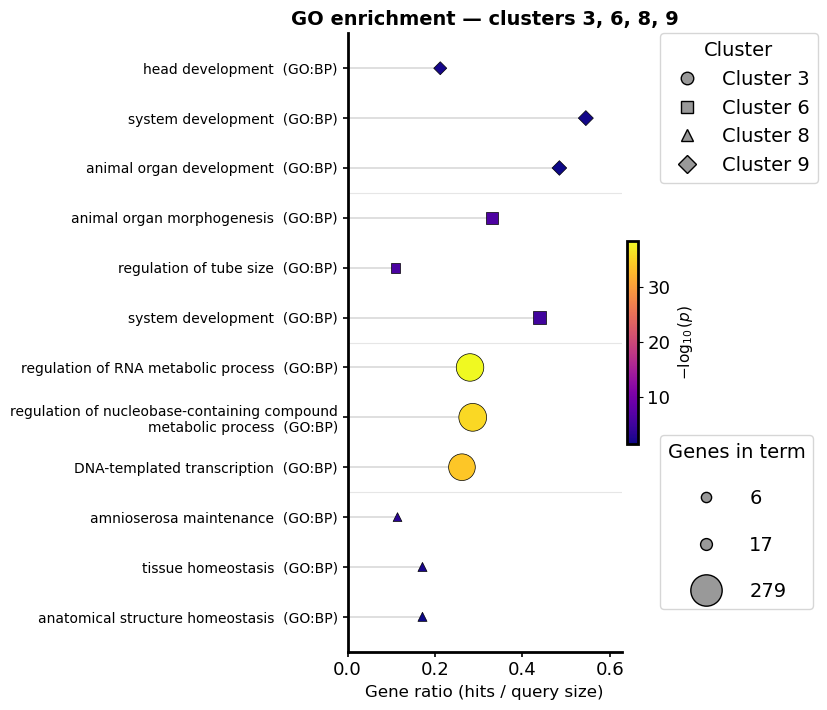

In [6]:
GENE_ID_COL = cm.detect_fbgn_col(result)

def go_enrichment(clusters, top_n=3, max_term_size=1000):
    from gprofiler import GProfiler
    gp = GProfiler(return_dataframe=True)
    background = result[GENE_ID_COL].dropna().astype(str).unique().tolist()
    parts = []
    for cl in clusters:
        query = result.loc[result['cluster'] == cl, GENE_ID_COL].dropna().astype(str).unique().tolist()
        res = gp.profile(organism='dmelanogaster', query=query, background=background,
                         sources=['GO:BP', 'GO:CC', 'GO:MF'], significance_threshold_method='g_SCS',
                         user_threshold=0.05, no_evidences=True)
        if res.empty:
            print(f'  cluster {cl}: no significant terms'); continue
        res = res.sort_values('p_value')
        res = res[res['term_size'] <= max_term_size].head(top_n).assign(cluster=cl)
        print(f'  cluster {cl} ({len(query)} genes): ' + '; '.join(res['name']))
        parts.append(res)
    return pd.concat(parts, ignore_index=True)

go_res = None
if GO_MODE in ('auto', 'live'):
    try:
        go_res = go_enrichment(GO_CLUSTERS)
    except Exception as e:
        if GO_MODE == 'live':
            raise
        print(f'g:Profiler query failed ({type(e).__name__}: {e}); using the reference file.')
if go_res is None:
    go_res = pd.read_csv(GO_REFERENCE)
    go_res = go_res[go_res['cluster'].isin(GO_CLUSTERS)]
    print(f'Using reference GO results from {GO_REFERENCE.name}')

# ── Lollipop: x = gene ratio, size = genes in term, colour = -log10 p, marker = cluster ──
d = go_res.copy()
d['gene_ratio'] = (d['precision'] if 'precision' in d else d['intersection_size'] / d['query_size']).astype(float)
d['neg_log10_pval'] = -np.log10(d['p_value'].clip(lower=1e-300))
order = [c for c in GO_CLUSTERS if c in set(d['cluster'])]
d['_rank'] = d['cluster'].map({c: -i for i, c in enumerate(order)})
d = d.sort_values(['_rank', 'neg_log10_pval']).reset_index(drop=True)

markers   = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
marker_of = {c: markers[i % len(markers)] for i, c in enumerate(sorted(order))}
labels = [textwrap.fill(f"{r['name']}  ({r['source']})", 45) for _, r in d.iterrows()]
y, x   = np.arange(len(d)), d['gene_ratio'].to_numpy(float)
sizes  = d['intersection_size'].to_numpy(float)
area   = lambda n: 40 + (n - sizes.min()) / (np.ptp(sizes) or 1) * 360
norm   = Normalize(d['neg_log10_pval'].min(), d['neg_log10_pval'].max())
colors = plt.get_cmap('plasma')(norm(d['neg_log10_pval']))

fig, ax = plt.subplots(figsize=(8.8, 0.46 * len(d) + 1.8))
for xi, yi in zip(x, y):
    ax.plot([0, xi], [yi, yi], color='0.85', lw=1.2, zorder=1)
for c in order:
    m = (d['cluster'] == c).to_numpy()
    ax.scatter(x[m], y[m], s=area(sizes[m]), marker=marker_of[c], c=colors[m],
               edgecolor='black', linewidth=0.5, zorder=3)
for b in np.where(d['cluster'].to_numpy()[:-1] != d['cluster'].to_numpy()[1:])[0] + 0.5:
    ax.axhline(b, color='0.9', lw=0.8, zorder=0)

ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=10)
ax.set_ylim(-0.7, len(d) - 0.3); ax.set_xlim(0, float(x.max()) * 1.15)
ax.set_xlabel('Gene ratio (hits / query size)', fontsize=12)
ax.set_title('GO enrichment — clusters ' + ', '.join(map(str, sorted(order))), fontsize=14, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False); ax.tick_params(width=1.2)
fig.colorbar(ScalarMappable(norm=norm, cmap='plasma'), ax=ax, fraction=0.035, pad=0.02).set_label(
    r'$-\log_{10}(p)$', fontsize=11)

picks = sorted(set(np.percentile(sizes, [10, 50, 100]).round().astype(int)))
size_handles = [Line2D([], [], marker='o', linestyle='', markeredgecolor='black', markerfacecolor='0.6',
                       markersize=np.sqrt(area(n) / np.pi) * 2, label=str(n)) for n in picks]
leg = ax.legend(handles=size_handles, title='Genes in term', loc='upper left', bbox_to_anchor=(1.14, 0.35),
                borderaxespad=0, labelspacing=1.4, handletextpad=1.2)
ax.add_artist(leg)
shape_handles = [Line2D([], [], marker=marker_of[c], linestyle='', markersize=9, markerfacecolor='0.6',
                        markeredgecolor='black', label=f'Cluster {c}') for c in sorted(order)]
ax.legend(handles=shape_handles, title='Cluster', loc='upper left', bbox_to_anchor=(1.14, 1.0), borderaxespad=0)
fig.tight_layout()
cm.save_fig(fig, OUT, 'fig3C_go_enrichment')
plt.show()

## Fig 3D — 7 hpf abundance of cluster 9, per line
Grey lines connect the same protein across lines; the top 10 proteins per line are labelled.

Saved fig3/fig3D_violin_7hpf_cluster9.pdf / .png


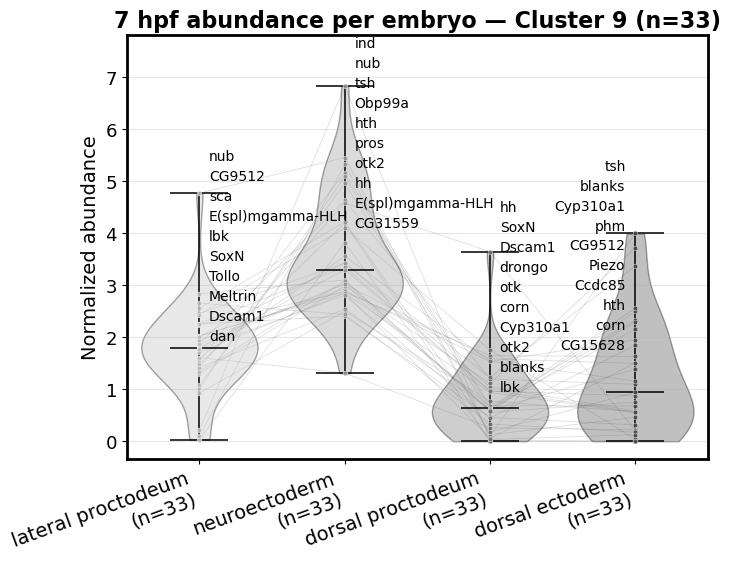

In [7]:
def declutter(ys, min_gap):
    """Push label positions apart so consecutive labels are at least min_gap apart."""
    ys = np.asarray(ys, float); adj = ys.copy()
    order = np.argsort(ys)
    for a, b in zip(order[:-1], order[1:]):
        if adj[b] - adj[a] < min_gap:
            adj[b] = adj[a] + min_gap
    return adj

LABEL_TOP, LABEL_FS = 10, 10
sub  = result[result['cluster'] == VIOLIN_CLUSTER]
tp   = timepoint_order.index('B4')
mat  = sub[[condition_columns[c][tp] for c in condition_order]].set_axis(condition_order, axis=1)
pos  = np.arange(1, len(condition_order) + 1)
grays = dict(zip(condition_order, ['0.75', '0.60', '0.45', '0.30']))

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for _, row in mat.dropna().iterrows():
    ax.plot(pos, row.to_numpy(), color='gray', alpha=0.25, linewidth=0.6, zorder=1)
data = [(p, c, mat[c].dropna().to_numpy()) for p, c in zip(pos, condition_order)]
vp = ax.violinplot([t[2] for t in data], positions=[t[0] for t in data], widths=0.8,
                   showmedians=True, showextrema=True)
for body, (_, c, _) in zip(vp['bodies'], data):
    body.set_facecolor(grays[c]); body.set_edgecolor('black'); body.set_alpha(0.35)
for key in ('cmedians', 'cbars', 'cmins', 'cmaxes'):
    vp[key].set_edgecolor('black'); vp[key].set_linewidth(1.1)
for p, c, yv in data:
    ax.scatter(np.full(yv.size, p), yv, s=12, color=grays[c], edgecolor='white', linewidth=0.3, alpha=0.9, zorder=3)

min_gap = 0.045 * np.ptp(mat.to_numpy()[np.isfinite(mat.to_numpy())]) * (LABEL_FS / 8)
top = -np.inf
for j, cond in enumerate(condition_order):
    s = mat[cond].dropna().sort_values(ascending=False).iloc[:LABEL_TOP]
    adj  = declutter(s.to_numpy(), min_gap)
    side = -1 if j == len(condition_order) - 1 else 1          # last line: labels on the left
    for idx, ya in zip(s.index, adj):
        ax.annotate(str(sub.at[idx, 'gene_symbol']), xy=(pos[j], ya), xytext=(7 * side, 0),
                    textcoords='offset points', fontsize=LABEL_FS, va='center',
                    ha='left' if side > 0 else 'right', zorder=4, clip_on=False)
    top = max(top, adj.max())
lo, hi = ax.get_ylim(); ax.set_ylim(lo, max(hi, top * 1.02))

ax.set_xlim(0.5, len(condition_order) + 0.5)
ax.set_xticks(pos)
ax.set_xticklabels([f'{c}\n(n={mat[c].notna().sum()})' for c in condition_order], rotation=20, ha='right', fontsize=14)
ax.set_ylabel('Normalized abundance')
ax.set_title(f'7 hpf abundance per embryo — Cluster {VIOLIN_CLUSTER} (n={len(sub)})', fontweight='bold')
ax.grid(True, axis='y', alpha=0.3)
cm.save_fig(fig, OUT, f'fig3D_violin_7hpf_cluster{VIOLIN_CLUSTER}')
plt.show()

## Fig 3E — % of proteome differentially abundant between lines at 7 hpf
Separate experiment from the time course: 4 replicates per line at 7 hpf (`protein_quant_2229_cns16_b4.tsv`).
Same statistics as Fig 2B (see `common.py`).

  b4 all: 5,953 proteins
  b4 NE_LP: 5,952 proteins
  b4 NE_DP: 5,945 proteins
  b4 NE_DE: 5,931 proteins
  b4 LP_DP: 5,945 proteins
  b4 LP_DE: 5,941 proteins
  b4 DP_DE: 5,911 proteins


NE_LP: 157/5952 = 2.6%
NE_DP: 245/5945 = 4.1%
NE_DE: 226/5931 = 3.8%
LP_DP: 151/5945 = 2.5%
LP_DE: 256/5941 = 4.3%
DP_DE: 217/5911 = 3.7%


Saved fig3/fig3E_pct_matrix_7hpf.pdf / .png


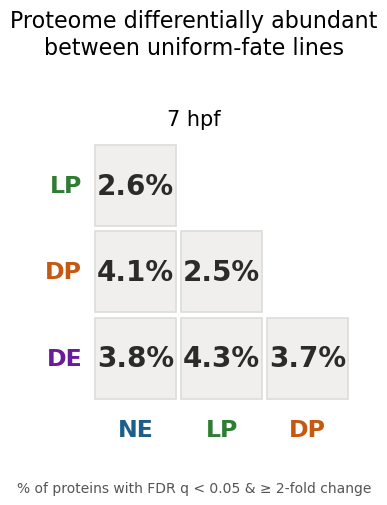

In [8]:
STAGE = 'b4'
datasets_7hpf = cm.build_mf_datasets(STAGE)
results_pair, counts_pair = cm.run_mf_comparisons(datasets_7hpf)          # Fig 3E
results_full, _           = cm.run_mf_comparisons(datasets_7hpf, 'all')   # Table S4

for key, (n_sig, total) in counts_pair.items():
    print(f'{key}: {n_sig}/{total} = {100 * n_sig / total:.1f}%')
fig = cm.plot_pct_matrix(counts_pair, STAGE)
cm.save_fig(fig, OUT, 'fig3E_pct_matrix_7hpf')
plt.show()

## Supplementary Tables S2, S3, S4
- **S2** — time course of all proteins with shared cluster assignment (line prefixes shortened to LP/DP/DE/NE).
- **S3** — the fate-specific clusters 6, 8 and 9 (subset of S2).
- **S4** — MF lines at 7 hpf, pairwise statistics.

In [9]:
table_cols = ['cluster', 'ProteinId', 'gene_symbol', 'gene_fullname', 'polypeptide_symbol', 'gene_ID', 'sumSN',
              'r6matt_0to1_norm', '2cr6_0to1_norm', 'ea21bot_0to1_norm', 'r67_0to1_norm',
              'r67_B0_norm', 'r6matt_B0_norm', '2cr6_B0_norm', 'ea21botspz_B0_norm',
              'r67_B2_norm', 'r6matt_B2_norm', '2cr6_B2_norm', 'ea21botspz_B2_norm',
              'r67_B4_norm', 'r6matt_B4_norm', '2cr6_B4_norm', 'ea21botspz_B4_norm']
line_short = {'r6matt': 'LP', '2cr6': 'DP', 'r67': 'NE', 'ea21botspz': 'DE', 'ea21bot': 'DE'}

def short_name(col):
    for pre, short in line_short.items():
        if col.startswith(pre + '_'):
            return short + col[len(pre):]
    return col

table_s2 = (result[table_cols]
            .sort_values(['cluster', 'gene_symbol', 'ProteinId'], na_position='last')
            .rename(columns=short_name).reset_index(drop=True))
cm.save_table(table_s2, 'Table_S2_MF_timecourse_clusters')

table_s3 = (table_s2[table_s2['cluster'].isin(FATE_CLUSTERS)]
            .assign(cluster=lambda d: d['cluster'].astype(int)).reset_index(drop=True))
cm.save_table(table_s3, 'Table_S3_MF_fate_cluster_proteins')
print(table_s3['cluster'].value_counts().reindex(FATE_CLUSTERS).to_string())

cm.save_table(cm.mf_stats_table(datasets_7hpf, results_full), 'Table_S4_MF_lines_7hpf')

Saved Table_S2_MF_timecourse_clusters.csv  (6,195 rows x 23 columns)
Saved Table_S3_MF_fate_cluster_proteins.csv  (159 rows x 23 columns)
cluster
6    91
8    35
9    33


Saved Table_S4_MF_lines_7hpf.csv  (5,953 rows x 42 columns)
